**Exercise 07.01. Data Preparation** (10-20 minutes)

In this exercise, you will work with the penguins dataset provided in 3 different files: original_penguins.csv, penguins_knn.csv, and penguins_no_chinstraps.csv.

The goal is to explore these datasets, identify differences, and use data visualization techniques to analyze their structure. 

This foundational step is critical in understanding how to handle and prepare data for further classification tasks.


**Explore the data:**

In [87]:
import pandas as pd
import matplotlib.pyplot as plt

original = pd.read_csv("../Assets/Exercise_07_data/original_penguins.csv")
knn = pd.read_csv("../Assets/Exercise_07_data/penguins_knn.csv")
no_chin = pd.read_csv("../Assets/Exercise_07_data/penguins_no_chinstraps.csv")

datasets = {"original": original, "knn": knn, "no_chinstraps": no_chin}

print("Shape: (rows and collumns)")
print(f"original: {original.shape}" )
print(f"knn: {knn.shape}")
print(f"no chin: {no_chin.shape}")
print()
   

Shape: (rows and collumns)
original: (344, 7)
knn: (344, 7)
no chin: (276, 7)



In [88]:
print("head:")
print("original:")
print(original.head(2))
print()

print("knn")
print(knn.head(2))
print()

print("no_chin")
print(no_chin.head(2))

head:
original:
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  

knn
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0     NaN  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  

no_chin
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  


In [89]:
print("amount of n/a-values:")

na_overview = pd.DataFrame({
    name: df.dtypes
    for name, df in datasets.items()
}).T

na_overview


amount of n/a-values:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
original,object,object,float64,float64,float64,float64,object
knn,object,object,float64,float64,float64,float64,object
no_chinstraps,object,object,float64,float64,float64,float64,object


In [90]:
print("amount of n/a-values:")

na_overview = pd.DataFrame({
    name: df.isna().sum()
    for name, df in datasets.items()
}).T

na_overview


amount of n/a-values:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
original,0,0,2,2,2,2,11
knn,102,0,2,2,2,2,11
no_chinstraps,0,0,2,2,2,2,11


In [92]:
summary = pd.DataFrame({
    name: {
        "rows": df.shape[0],
        "columns": df.shape[1],
        "n_species": df["species"].nunique(), # NaN is excluded by default
        "species_values": ", ".join(df["species"].dropna().unique()),
        "missing_species": df["species"].isna().sum(),
        "total_missing_cells": df.isna().sum().sum(),
    }
    for name, df in datasets.items()
}).T          # transpose so datasets are rows

summary

,rows,columns,n_species,species_values,missing_species,total_missing_cells
original,344,7,3,"Adelie, Chinstrap, Gentoo",0,19
knn,344,7,3,"Adelie, Chinstrap, Gentoo",102,121
no_chinstraps,276,7,2,"Adelie, Gentoo",0,19


**Compare the data sets:** 

Characteristics:
of the three data sets: original, knn and no_chin
* The 3 data files have same amount of columns (7) and matching collumn names and data types.
* Original and knn both have 344 rows, no chin 276

**no_chinstraps is the simplest** in terms of features, as it excludes all rows of chinstrap.
The result is a data set with only two species.

Missing data (na values):
* knn have na value in collumn *Species* on 102 rows
* no_chin does not have any *Species* data
* Other than that the amounts of missing data (na values) match, however not certain that the same rows miss the data among the 3 files: \
    island                0 \
    bill_length_mm        2 \
    bill_depth_mm         2 \
    flipper_length_mm     2 \
    body_mass_g           2 \
    sex                  11 

**Visualize the datasets:**

* Create basic plots (e.g., histograms or scatter plots) to gain insights into the distributions of key features like bill length, bill depth, flipper length, and
body mass.
* Use the visualizations to analyze and describe which dataset might be most

suitable for different classification methods such as k-NN, regression, or de-
cision trees.

• Expected Output/Questions:
1. What are the main differences between the three datasets?
2. Which dataset has missing species entries?
3. Which dataset do you find to be the simplest in terms of features?

4. Provide a brief description of the visual insights obtained from the dataset, par-
ticularly in relation to classification methods.

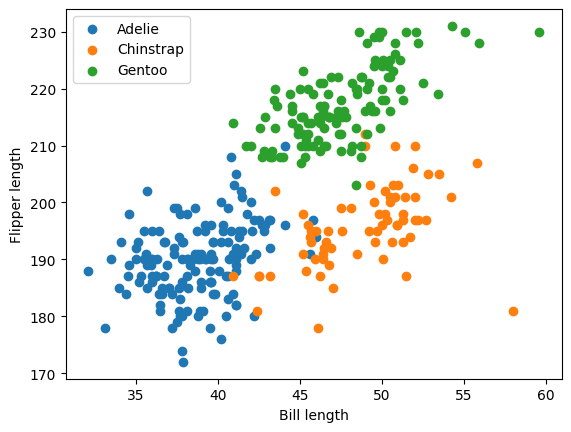

In [ ]:
for species, group in original.groupby("species"):
    plt.scatter(group["bill_length_mm"], group["flipper_length_mm"], label=species)
plt.xlabel("Bill length")
plt.ylabel("Flipper length")
plt.legend()
plt.show()